In [1]:
import sys  
sys.path.insert(0, './')

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
from statistics import NormalDist

In [27]:



price_files = [
    "../data/prices_round_1_day_-2.csv",
    "../data/prices_round_2_day_-1.csv",
    "../data/prices_round_3_day_0.csv",
    "../data/prices_round_4_day_1.csv",
    "../data/prices_round_5_day_2.csv",
    "../data/prices_round_5_day_3.csv",
    "../data/prices_round_5_day_4.csv",
]

# Map day index to timestamp offset
day_offsets = {
    0: 0,
    1: 1_000_000,
    2: 2_000_000,
    3 : 3_000_000,
    4: 4_000_000,
    5:5_000_000,
    6:6_000_000,
    7:7_000_000
}

dfs = []

for i, file in enumerate(price_files):
    df = pd.read_csv(file)
    df = df.iloc[:, 0].str.split(";", expand=True)
    df.columns = [
        "day", "timestamp", "product",
        "bid_price_1", "bid_volume_1", "bid_price_2", "bid_volume_2", "bid_price_3", "bid_volume_3",
        "ask_price_1", "ask_volume_1", "ask_price_2", "ask_volume_2", "ask_price_3", "ask_volume_3",
        "mid_price", "profit_and_loss"
    ]
    
    # Convert numeric columns
    numeric_cols = df.columns.difference(["day", "timestamp", "product"])
    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
    
    # Convert and shift timestamp
    df["timestamp"] = df["timestamp"].astype(int) + day_offsets[i]
    
    dfs.append(df)

# Concatenate all days into one dataframe
df = pd.concat(dfs, ignore_index=True)

In [ ]:
ink_df = df.loc[df['product']=='SQUID_INK'].copy()
kelp_df = df.loc[df['product']=='KELP'].copy()

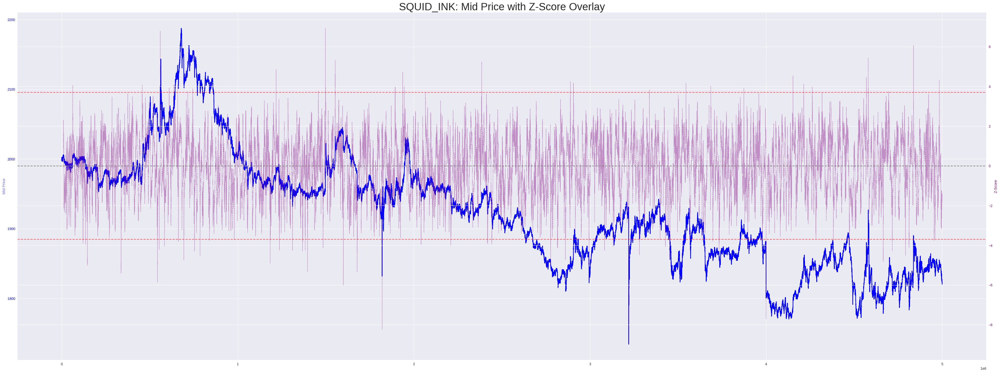

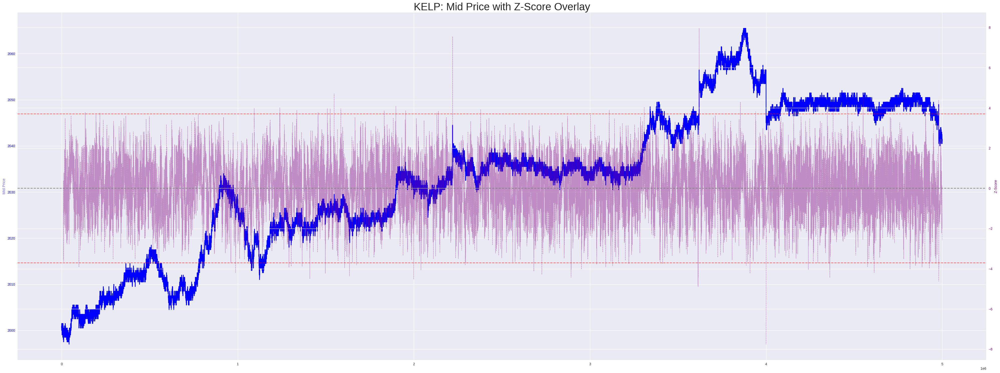

In [ ]:
import matplotlib.pyplot as plt

# Define rolling window
window = 100

# =========================
# SQUID INK PRICE EVOLUTION
# =========================
# ink_df = df.loc[df['product'] == 'SQUID_INK'].copy()

# Compute mid price, moving average, std, and z-score
ink_df['mid_price'] = (ink_df['ask_price_1'] + ink_df['bid_price_1']) / 2
ink_df['ma'] = ink_df['mid_price'].rolling(window).mean()
ink_df['std'] = ink_df['mid_price'].rolling(window).std()
ink_df['z_score'] = (ink_df['mid_price'] - ink_df['ma']) / ink_df['std']
ink_df['relative_diff'] = 100 * (ink_df['mid_price'] - ink_df['ma']) / ink_df['ma']

# Plot for SQUID_INK
fig, ax1 = plt.subplots(figsize=(40, 15))

ax2 = ax1.twinx()
ax2.plot(ink_df['timestamp'], ink_df['z_score'], label='Z-Score',
         color='purple', linestyle='--', linewidth=1, alpha=0.4, zorder=1)
ax2.axhline(0, linestyle='--', color='gray', zorder=1)
ax2.axhline(3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.axhline(-3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.set_ylabel("Z-Score", color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

ax1.plot(ink_df['timestamp'], ink_df['mid_price'],
         label='Relative % Difference from MA', color='blue', linewidth=2, zorder=2)
ax1.set_ylabel("Mid Price", color='blue', alpha=0.6)
ax1.tick_params(axis='y', labelcolor='blue')

plt.title("SQUID_INK: Mid Price with Z-Score Overlay", fontsize=30)
fig.tight_layout()
plt.grid(True)
plt.show()


# ====================
# KELP PRICE EVOLUTION
# ====================
# kelp_df = df.loc[df['product'] == 'KELP'].copy()

# Compute mid price, moving average, std, and z-score
kelp_df['mid_price'] = (kelp_df['ask_price_1'] + kelp_df['bid_price_1']) / 2
kelp_df['ma'] = kelp_df['mid_price'].rolling(window).mean()
kelp_df['std'] = kelp_df['mid_price'].rolling(window).std()
kelp_df['z_score'] = (kelp_df['mid_price'] - kelp_df['ma']) / kelp_df['std']
kelp_df['relative_diff'] = 100 * (kelp_df['mid_price'] - kelp_df['ma']) / kelp_df['ma']

# Plot for KELP
fig, ax1 = plt.subplots(figsize=(40, 15))

ax2 = ax1.twinx()
ax2.plot(kelp_df['timestamp'], kelp_df['z_score'], label='Z-Score',
         color='purple', linestyle='--', linewidth=1, alpha=0.4, zorder=1)
ax2.axhline(0, linestyle='--', color='gray', zorder=1)
ax2.axhline(3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.axhline(-3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.set_ylabel("Z-Score", color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

ax1.plot(kelp_df['timestamp'], kelp_df['mid_price'],
         label='Relative % Difference from MA', color='blue', linewidth=2, zorder=2)
ax1.set_ylabel("Mid Price", color='blue', alpha=0.6)
ax1.tick_params(axis='y', labelcolor='blue')

plt.title("KELP: Mid Price with Z-Score Overlay", fontsize=30)
fig.tight_layout()
plt.grid(True)
plt.show()


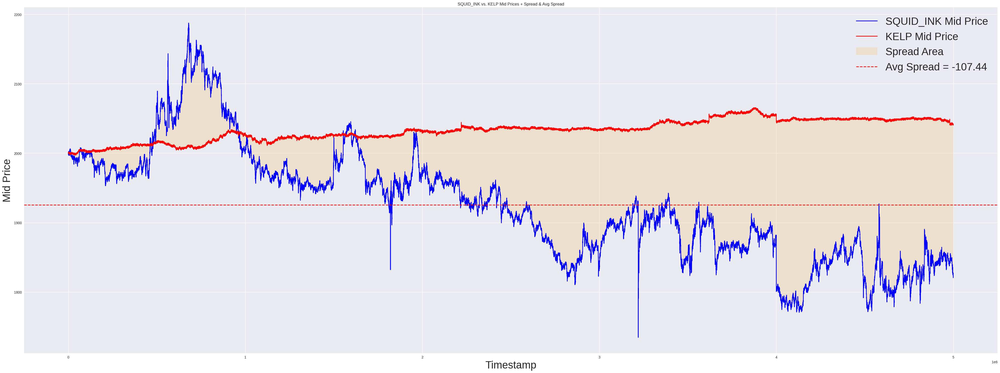

In [ ]:

# Calculate mid prices
ink_df['mid_price'] = (ink_df['ask_price_1'] + ink_df['bid_price_1']) / 2
kelp_df['mid_price'] = (kelp_df['ask_price_1'] + kelp_df['bid_price_1']) / 2

# Merge on timestamp to align both series
merged_df = pd.merge(
    ink_df[['timestamp', 'mid_price']],
    kelp_df[['timestamp', 'mid_price']],
    on='timestamp',
    suffixes=('_ink', '_kelp')
)

# Calculate Spread
merged_df['spread'] = merged_df['mid_price_ink'] - merged_df['mid_price_kelp']
avg_spread = merged_df['spread'].mean()

# === Plot ===
fig, ax = plt.subplots(figsize=(40, 15))

# Plot mid prices
ax.plot(merged_df['timestamp'], merged_df['mid_price_ink'],
        label='SQUID_INK Mid Price', color='blue', linewidth=2)
ax.plot(merged_df['timestamp'], merged_df['mid_price_kelp'],
        label='KELP Mid Price', color='red', linewidth=2)

# Plot spread as shaded area
ax.fill_between(merged_df['timestamp'], 
                merged_df['mid_price_ink'], 
                merged_df['mid_price_kelp'],
                color='orange', alpha=0.15, label='Spread Area')

# Add average spread as horizontal line
ax.axhline(y=avg_spread + merged_df['mid_price_kelp'].mean(),  # approximate location
           linestyle='--', color='red', linewidth=2,
           label=f'Avg Spread = {avg_spread:.2f}')

ax.set_title("SQUID_INK vs. KELP Mid Prices + Spread & Avg Spread")
ax.set_xlabel("Timestamp", fontsize=30)
ax.set_ylabel("Mid Price", fontsize=30)
ax.legend(fontsize=30)
ax.grid(True)
fig.tight_layout()
plt.show()


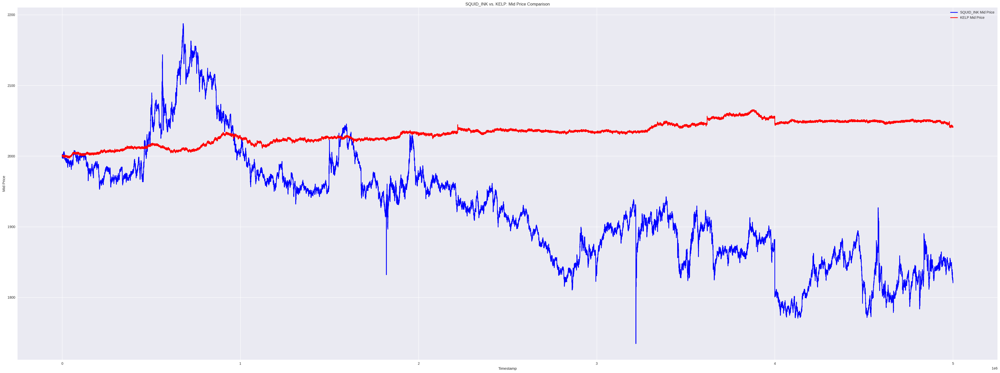

In [ ]:
# Calculate mid prices
ink_df['mid_price'] = (ink_df['ask_price_1'] + ink_df['bid_price_1']) / 2
kelp_df['mid_price'] = (kelp_df['ask_price_1'] + kelp_df['bid_price_1']) / 2

# Merge on timestamp to align both series
merged_df = pd.merge(ink_df[['timestamp', 'mid_price']], kelp_df[['timestamp', 'mid_price']],
                     on='timestamp', suffixes=('_ink', '_kelp'))

# === Plot both mid prices ===
plt.figure(figsize=(40, 15))

plt.plot(merged_df['timestamp'], merged_df['mid_price_ink'], label='SQUID_INK Mid Price',
         color='blue', linewidth=2)
plt.plot(merged_df['timestamp'], merged_df['mid_price_kelp'], label='KELP Mid Price',
         color='red', linewidth=2)

plt.title("SQUID_INK vs. KELP: Mid Price Comparison")
plt.xlabel("Timestamp")
plt.ylabel("Mid Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


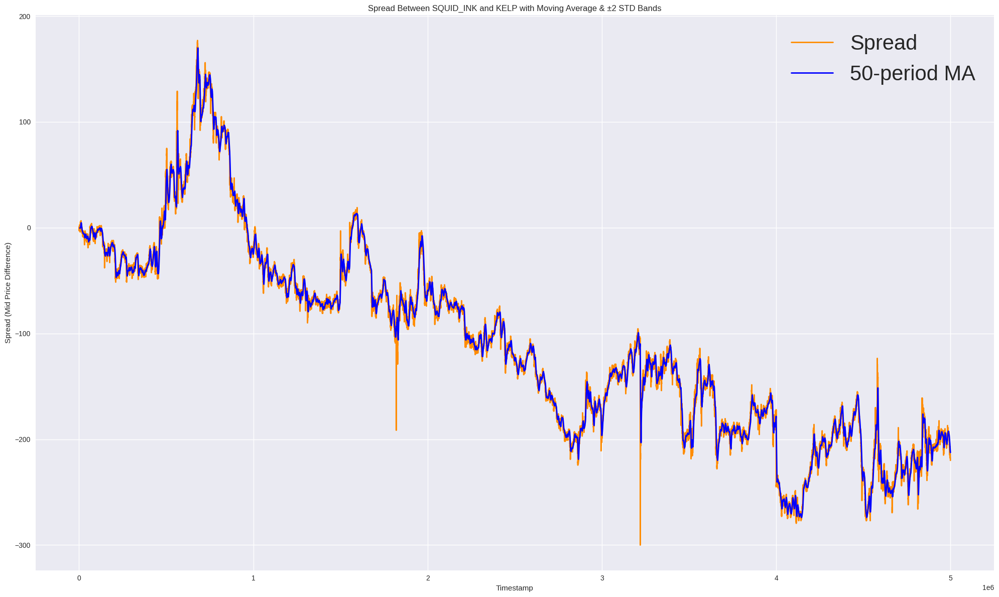

In [ ]:
# === Prepare Data ===
ink_df = df.loc[df['product'] == 'SQUID_INK'].copy()
kelp_df = df.loc[df['product'] == 'KELP'].copy()

ink_df['mid_price'] = (ink_df['ask_price_1'] + ink_df['bid_price_1']) / 2
kelp_df['mid_price'] = (kelp_df['ask_price_1'] + kelp_df['bid_price_1']) / 2

# === Merge data on timestamp ===
merged_df = pd.merge(
    ink_df[['timestamp', 'mid_price']],
    kelp_df[['timestamp', 'mid_price']],
    on='timestamp',
    suffixes=('_ink', '_kelp')
)

# === Compute spread and its moving average/std ===
merged_df['spread'] = merged_df['mid_price_ink'] - merged_df['mid_price_kelp']

spread_window = 50
merged_df['spread_ma'] = merged_df['spread'].rolling(spread_window).mean()
merged_df['spread_std'] = merged_df['spread'].rolling(spread_window).std()

# === Plot ===
plt.figure(figsize=(20, 12))

# Plot spread
plt.plot(merged_df['timestamp'], merged_df['spread'], label='Spread', color='darkorange', linewidth=2)

# Plot moving average of spread
plt.plot(merged_df['timestamp'], merged_df['spread_ma'], label=f'{spread_window}-period MA', color='blue', linewidth=2)

# Plot upper and lower bounds (mean ± 2 std)
#plt.plot(merged_df['timestamp'], merged_df['spread_ma'] + 2*merged_df['spread_std'],
#         label='+2 STD', linestyle='--', color='green', alpha=0.6)
#plt.plot(merged_df['timestamp'], merged_df['spread_ma'] - 2*merged_df['spread_std'],
#         label='-2 STD', linestyle='--', color='red', alpha=0.6)

plt.title("Spread Between SQUID_INK and KELP with Moving Average & ±2 STD Bands")
plt.xlabel("Timestamp")
plt.ylabel("Spread (Mid Price Difference)")
plt.legend(fontsize=30)
plt.grid(True)
plt.tight_layout()
plt.show()


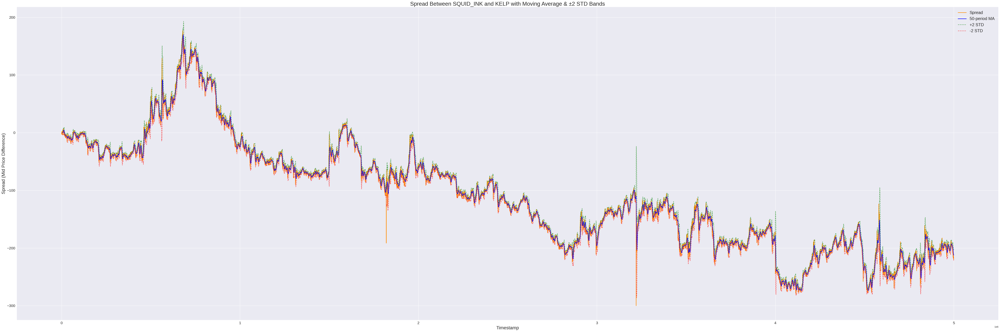

In [ ]:
# === Plot with Bigger Size ===
plt.figure(figsize=(60, 20))  # Increased from (40, 15)

# Plot spread
plt.plot(merged_df['timestamp'], merged_df['spread'], label='Spread', color='darkorange', linewidth=2)

# Plot moving average of spread
plt.plot(merged_df['timestamp'], merged_df['spread_ma'], label=f'{spread_window}-period MA', color='blue', linewidth=2)

# Plot upper and lower bounds (mean ± 2 std)
plt.plot(merged_df['timestamp'], merged_df['spread_ma'] + 2*merged_df['spread_std'],
         label='+2 STD', linestyle='--', color='green', alpha=0.6)
plt.plot(merged_df['timestamp'], merged_df['spread_ma'] - 2*merged_df['spread_std'],
         label='-2 STD', linestyle='--', color='red', alpha=0.6)

plt.title("Spread Between SQUID_INK and KELP with Moving Average & ±2 STD Bands", fontsize=24)
plt.xlabel("Timestamp", fontsize=20)
plt.ylabel("Spread (Mid Price Difference)", fontsize=20)
plt.legend(fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import plotly.graph_objects as go

# === Create figure ===
fig = go.Figure()

# Spread line
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread'],
    mode='lines', name='Spread',
    line=dict(color='darkorange')
))

# Moving average
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread_ma'],
    mode='lines', name=f'{spread_window}-period MA',
    line=dict(color='blue')
))


# === Layout ===
fig.update_layout(
    title="Interactive Spread Between SQUID_INK and KELP with MA & ±2 STD Bands",
    xaxis_title="Timestamp",
    yaxis_title="Spread (Mid Price Difference)",
    legend=dict(font=dict(size=14)),
    height=800,
    width=2000,
    template='plotly_white'
)

# === Show interactive plot ===
fig.show()


In [ ]:
merged_df['z_score'] = (merged_df['spread'] - merged_df['spread_ma']) / merged_df['spread_std']


In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# === Compute Z-score ===
merged_df['z_score'] = (merged_df['spread'] - merged_df['spread_ma']) / merged_df['spread_std']

# === Create subplots: 2 rows (Spread, Z-score) ===
fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                    vertical_spacing=0.05,
                    subplot_titles=("Spread Between SQUID_INK and KELP", "Z-Score of the Spread"))

# === Plot Spread and its Moving Average ===
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread'],
    mode='lines', name='Spread',
    line=dict(color='darkorange')
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread_ma'],
    mode='lines', name=f'{spread_window}-period MA',
    line=dict(color='blue')
), row=1, col=1)

# ±2 STD bands
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread_ma'] + 2 * merged_df['spread_std'],
    mode='lines', name='+2 STD',
    line=dict(dash='dash', color='green')
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread_ma'] - 2 * merged_df['spread_std'],
    mode='lines', name='-2 STD',
    line=dict(dash='dash', color='red')
), row=1, col=1)

# === Plot Z-score ===
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['z_score'],
    mode='lines', name='Z-Score',
    line=dict(color='purple')
), row=2, col=1)

# Horizontal thresholds for Z-score (e.g., entry signals)
fig.add_hline(y=2, line_dash="dash", line_color="green", row=2, col=1)
fig.add_hline(y=-2, line_dash="dash", line_color="red", row=2, col=1)
fig.add_hline(y=0, line_dash="dot", line_color="gray", row=2, col=1)

# === Update layout ===
fig.update_layout(
    height=1000,
    width=2000,
    title="Spread & Z-Score Between SQUID_INK and KELP",
    showlegend=True,
    template='plotly_white'
)

fig.update_yaxes(title_text="Spread", row=1, col=1)
fig.update_yaxes(title_text="Z-Score", row=2, col=1)

fig.show()


In [ ]:
merged_df['z_score'] = (merged_df['spread'] - merged_df['spread_ma']) / merged_df['spread_std']

# === Create a figure with secondary y-axis ===
fig = make_subplots(specs=[[{"secondary_y": True}]])

# === Primary Y-axis: Spread and its Moving Average ===
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread'],
    mode='lines', name='Spread',
    line=dict(color='darkorange'),
    opacity=0.8  # Adding some transparency to spread
), secondary_y=False)

fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread_ma'],
    mode='lines', name=f'{spread_window}-period MA',
    line=dict(color='blue'),
    opacity=0.8  # Adding some transparency to MA
), secondary_y=False)

# === Secondary Y-axis: Z-score with higher opacity ===
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['z_score'],
    mode='lines', name='Z-Score',
    line=dict(color='purple', width=2.5),
    opacity=0.3  # Reduced opacity for Z-score as per your example
), secondary_y=True)

# Add horizontal thresholds for Z-score on the secondary y-axis
fig.add_hline(y=2, line_dash="dash", line_color="green", secondary_y=True, opacity=0.7)
fig.add_hline(y=-2, line_dash="dash", line_color="red", secondary_y=True, opacity=0.7)
fig.add_hline(y=0, line_dash="dot", line_color="gray", secondary_y=True, opacity=0.5)

# === Update layout ===
fig.update_layout(
    height=800,
    width=1600,
    title="Superposed Spread & Z-Score Between SQUID_INK and KELP",
    showlegend=True,
    template='plotly_white',
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

# Calculate Z-score range for fixed axis scaling
z_min = merged_df['z_score'].min()
z_max = merged_df['z_score'].max()
# Add some padding to the range (10%)
z_padding = (z_max - z_min) * 0.1
z_range = [z_min - z_padding, z_max + z_padding]

# Set y-axes titles and fix scaling for Z-score axis
fig.update_yaxes(title_text="Spread", secondary_y=False)
fig.update_yaxes(
    title_text="Z-Score", 
    secondary_y=True,
    range=z_range,  # Set fixed range for Z-score
    fixedrange=False,  # Allow zooming but will maintain proper scale
    showgrid=True,     # Show grid lines for Z-score axis
    gridcolor='rgba(128, 0, 128, 0.1)',  # Light purple grid to match Z-score line
    zeroline=True,     # Show zero line
    zerolinewidth=1.5,
    zerolinecolor='rgba(128, 0, 128, 0.3)'
)

# Add a light background color to the secondary y-axis area to visually distinguish it
fig.update_layout(
    plot_bgcolor='rgba(240,240,240,0.95)'
)

# Ensure proper scales are maintained when zooming on data
fig.update_layout(
    xaxis=dict(
        domain=[0.0, 0.94]  # Give slightly more space for the secondary y-axis
    )
)

fig.show()

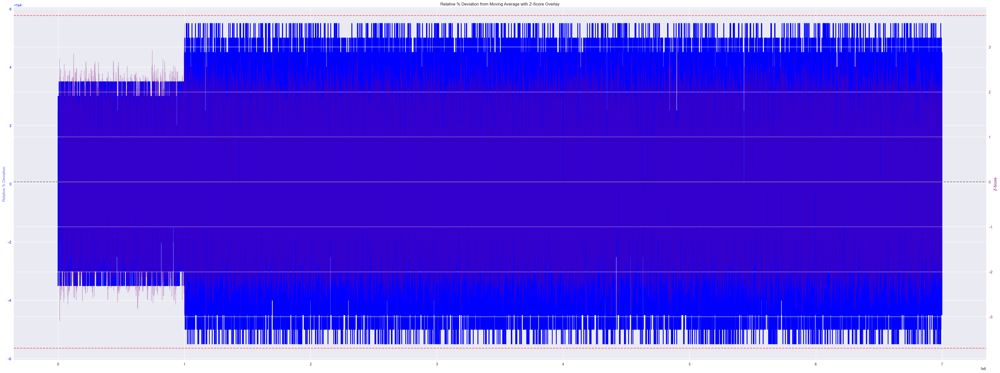

In [ ]:
RAINFOREST_RESIN_df = df.loc[df['product']=='RAINFOREST_RESIN'].copy()
window = 100  # rolling window

# === Compute mid price, moving average, std, and percentage deviation ===
RAINFOREST_RESIN_df['mid_price'] = (RAINFOREST_RESIN_df['ask_price_1'] + RAINFOREST_RESIN_df['bid_price_1']) / 2
RAINFOREST_RESIN_df['ma'] = RAINFOREST_RESIN_df['mid_price'].rolling(window).mean()
RAINFOREST_RESIN_df['std'] = RAINFOREST_RESIN_df['mid_price'].rolling(window).std()
RAINFOREST_RESIN_df['z_score'] = (RAINFOREST_RESIN_df['mid_price'] - RAINFOREST_RESIN_df['ma']) / RAINFOREST_RESIN_df['std']
RAINFOREST_RESIN_df['relative_diff'] = 100 * (RAINFOREST_RESIN_df['mid_price'] - RAINFOREST_RESIN_df['ma']) / RAINFOREST_RESIN_df['ma']

# === Plot: Relative % Deviation and Z-score ===
fig, ax1 = plt.subplots(figsize=(40, 15))

# Z-score (background)
ax2 = ax1.twinx()
ax2.plot(RAINFOREST_RESIN_df['timestamp'], RAINFOREST_RESIN_df['z_score'], label='Z-Score',
         color='purple', linestyle='--', linewidth=1, alpha=0.4, zorder=1)
ax2.axhline(0, linestyle='--', color='gray', zorder=1)
ax2.axhline(3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.axhline(-3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.set_ylabel("Z-Score", color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

# Relative % deviation (foreground)
ax1.plot(RAINFOREST_RESIN_df['timestamp'], RAINFOREST_RESIN_df['mid_price'],
         label='Relative % Difference from MA', color='blue', linewidth=2, zorder=2)
ax1.set_ylabel("Relative % Deviation", color='blue', alpha=0.6)
ax1.tick_params(axis='y', labelcolor='blue')

plt.title("Relative % Deviation from Moving Average with Z-Score Overlay")
fig.tight_layout()
plt.grid(True)
plt.show()


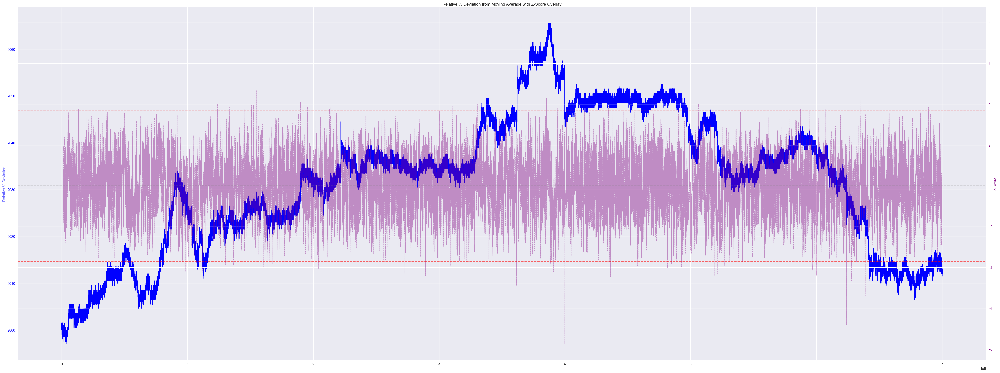

In [ ]:
#KELP PRICE EVOLUTION


KELP_df = df.loc[df['product']=='KELP'].copy()
window = 100  # rolling window

# === Compute mid price, moving average, std, and percentage deviation ===
KELP_df['mid_price'] = (KELP_df['ask_price_1'] + KELP_df['bid_price_1']) / 2
KELP_df['ma'] = KELP_df['mid_price'].rolling(window).mean()
KELP_df['std'] = KELP_df['mid_price'].rolling(window).std()
KELP_df['z_score'] = (KELP_df['mid_price'] - KELP_df['ma']) / KELP_df['std']
KELP_df['relative_diff'] = 100 * (KELP_df['mid_price'] - KELP_df['ma']) / KELP_df['ma']

# === Plot: Relative % Deviation and Z-score ===
fig, ax1 = plt.subplots(figsize=(40, 15))

# Z-score (background)
ax2 = ax1.twinx()
ax2.plot(KELP_df['timestamp'], KELP_df['z_score'], label='Z-Score',
         color='purple', linestyle='--', linewidth=1, alpha=0.4, zorder=1)
ax2.axhline(0, linestyle='--', color='gray', zorder=1)
ax2.axhline(3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.axhline(-3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.set_ylabel("Z-Score", color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

# Relative % deviation (foreground)
ax1.plot(KELP_df['timestamp'], KELP_df['mid_price'],
         label='Relative % Difference from MA', color='blue', linewidth=2, zorder=2)
ax1.set_ylabel("Relative % Deviation", color='blue', alpha=0.6)
ax1.tick_params(axis='y', labelcolor='blue')

plt.title("Relative % Deviation from Moving Average with Z-Score Overlay")
fig.tight_layout()
plt.grid(True)
plt.show()


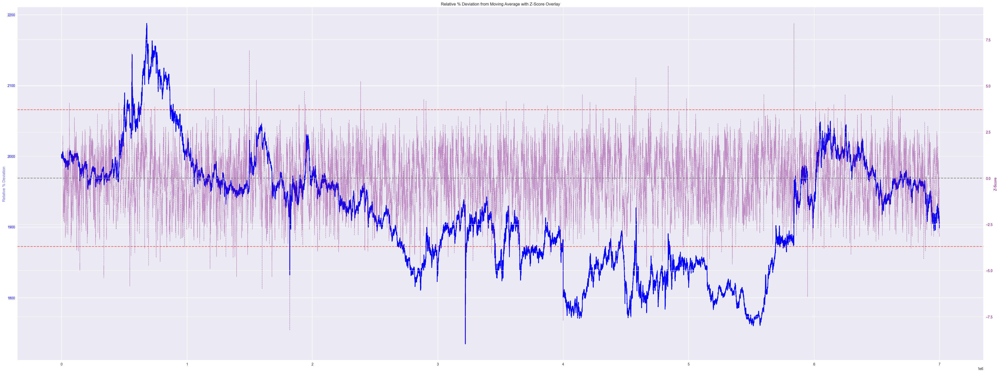

In [ ]:
#SQUID INK PRICE EVOLUTION


SQUID_INK_df = df.loc[df['product']=='SQUID_INK'].copy()
window = 100  # rolling window

# === Compute mid price, moving average, std, and percentage deviation ===
SQUID_INK_df['mid_price'] = (SQUID_INK_df['ask_price_1'] + SQUID_INK_df['bid_price_1']) / 2
SQUID_INK_df['ma'] = SQUID_INK_df['mid_price'].rolling(window).mean()
SQUID_INK_df['std'] = SQUID_INK_df['mid_price'].rolling(window).std()
SQUID_INK_df['z_score'] = (SQUID_INK_df['mid_price'] - SQUID_INK_df['ma']) / SQUID_INK_df['std']
SQUID_INK_df['relative_diff'] = 100 * (SQUID_INK_df['mid_price'] - SQUID_INK_df['ma']) / SQUID_INK_df['ma']

# === Plot: Relative % Deviation and Z-score ===
fig, ax1 = plt.subplots(figsize=(40, 15))

# Z-score (background)
ax2 = ax1.twinx()
ax2.plot(SQUID_INK_df['timestamp'], SQUID_INK_df['z_score'], label='Z-Score',
         color='purple', linestyle='--', linewidth=1, alpha=0.4, zorder=1)
ax2.axhline(0, linestyle='--', color='gray', zorder=1)
ax2.axhline(3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.axhline(-3.7, linestyle='--', color='red', alpha=0.6, zorder=1)
ax2.set_ylabel("Z-Score", color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

# Relative % deviation (foreground)
ax1.plot(SQUID_INK_df['timestamp'], SQUID_INK_df['mid_price'],
         label='Relative % Difference from MA', color='blue', linewidth=2, zorder=2)
ax1.set_ylabel("Relative % Deviation", color='blue', alpha=0.6)
ax1.tick_params(axis='y', labelcolor='blue')

plt.title("Relative % Deviation from Moving Average with Z-Score Overlay")
fig.tight_layout()
plt.grid(True)
plt.show()

Spread mean over all days: 5.251791666666667
before mean 29.26


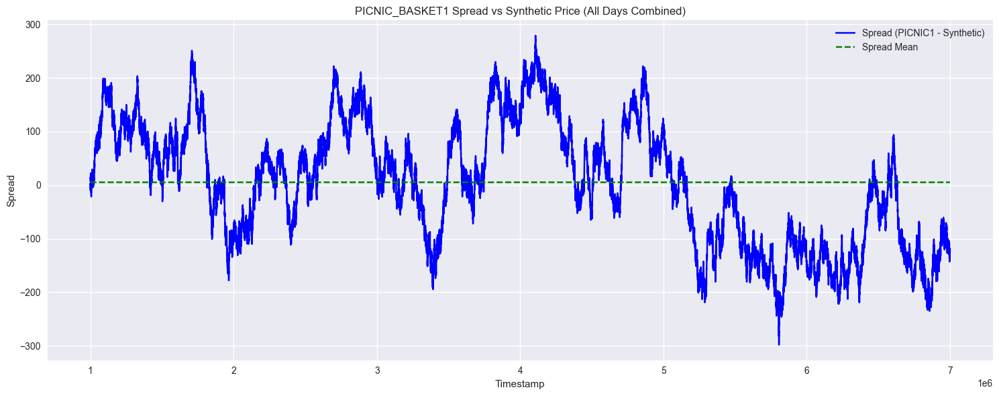

In [ ]:
#SPREAD PICNIC 1

import matplotlib.pyplot as plt
import pandas as pd

# Combine all your daily DataFrames into one thats df

# Filter by product
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Merge on timestamp
merged_df = picnic1_df.merge(croissant_df, on='timestamp', how='inner')\
                      .merge(djembes_df, on='timestamp', how='inner')\
                      .merge(jams_df, on='timestamp', how='inner')\
                      .dropna()

# Calculate synthetic price and spread
merged_df['weighted'] = 6 * merged_df['croissant'] + 1 * merged_df['djembes'] + 3 * merged_df['jams']
merged_df['spread'] = merged_df['picnic1'] - merged_df['weighted']

# Compute overall spread mean
spread_mean = merged_df['spread'].mean()
print("Spread mean over all days:", spread_mean)
print("before mean" , '29.26')

# Add mean line for plotting
merged_df['mean'] = spread_mean

# Plot
plt.figure(figsize=(15, 6))
plt.plot(merged_df['timestamp'], merged_df['spread'], label='Spread (PICNIC1 - Synthetic)', color='blue')
plt.plot(merged_df['timestamp'], merged_df['mean'], label='Spread Mean', color='green', linestyle='--')

plt.title("PICNIC_BASKET1 Spread vs Synthetic Price (All Days Combined)")
plt.xlabel("Timestamp")
plt.ylabel("Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Spread mean over all days: 53.13415
 before mean : 44.99


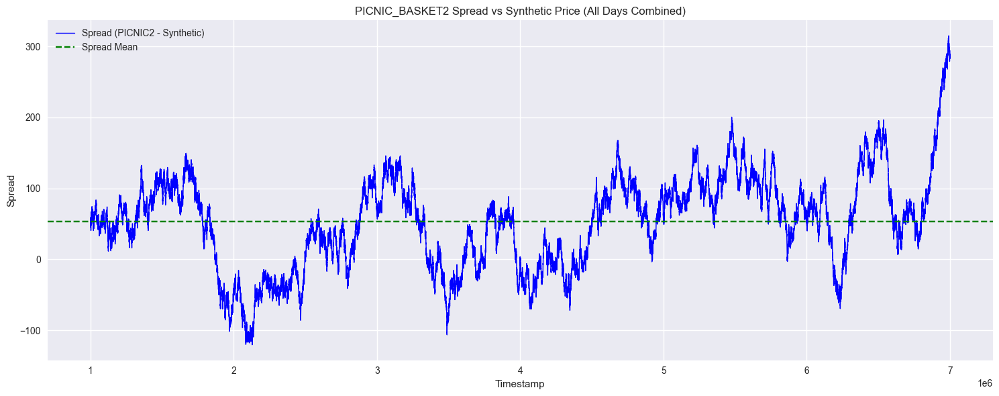

In [ ]:
#spread PICNIC2

import pandas as pd
import matplotlib.pyplot as plt




# Step 2: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 3: Merge all into one DataFrame on timestamp
merged_df = picnic2_df.merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Step 4: Compute synthetic price and spread
merged_df['weighted'] = (
    4 * merged_df['croissant'] +
    0 * merged_df['djembes'] +
    2 * merged_df['jams']
)
merged_df['spread'] = merged_df['picnic2'] - merged_df['weighted']

# Step 5: Compute and print overall spread mean
spread_mean = merged_df['spread'].mean()
print("Spread mean over all days:", spread_mean)
print(" before mean : 44.99")

# Step 6: Plot spread and mean line
plt.figure(figsize=(15, 6))

plt.plot(merged_df['timestamp'], merged_df['spread'], label='Spread (PICNIC2 - Synthetic)', color='blue', linewidth=1)

# Draw mean as dashed horizontal line
plt.axhline(y=spread_mean, color='green', linestyle='--', label='Spread Mean')

plt.title("PICNIC_BASKET2 Spread vs Synthetic Price (All Days Combined)")
plt.xlabel("Timestamp")
plt.ylabel("Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Arbitrage Spread Mean over all days: 101.01650833333333
before mean : 60.71


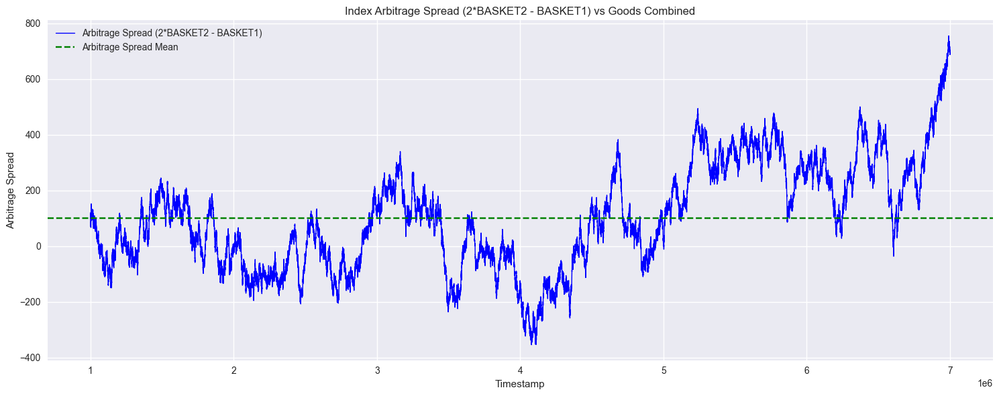

In [ ]:
#SPREAD 2BSKT2 - BSKT1

import pandas as pd
import matplotlib.pyplot as plt



# Step 2: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 3: Merge all into one DataFrame on timestamp
merged_df = picnic2_df.merge(picnic1_df, on='timestamp', how='inner') \
                      .merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Step 4: Compute synthetic price and spread
merged_df['arbitrage_spread'] = (
    2 * merged_df['picnic2'] -
    1 * merged_df['picnic1'] -
    2 * merged_df['croissant'] -
    1 * merged_df['jams'] +
    1 * merged_df['djembes']
)

# Step 5: Compute and print overall arbitrage spread mean
arbitrage_spread_mean = merged_df['arbitrage_spread'].mean()
print("Arbitrage Spread Mean over all days:", arbitrage_spread_mean)
print("before mean : 60.71")

# Step 6: Plot arbitrage spread and mean line
plt.figure(figsize=(15, 6))

plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread'], label='Arbitrage Spread (2*BASKET2 - BASKET1)', color='blue', linewidth=1)

# Draw mean as dashed horizontal line
plt.axhline(y=arbitrage_spread_mean, color='green', linestyle='--', label='Arbitrage Spread Mean')

plt.title("Index Arbitrage Spread (2*BASKET2 - BASKET1) vs Goods Combined")
plt.xlabel("Timestamp")
plt.ylabel("Arbitrage Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

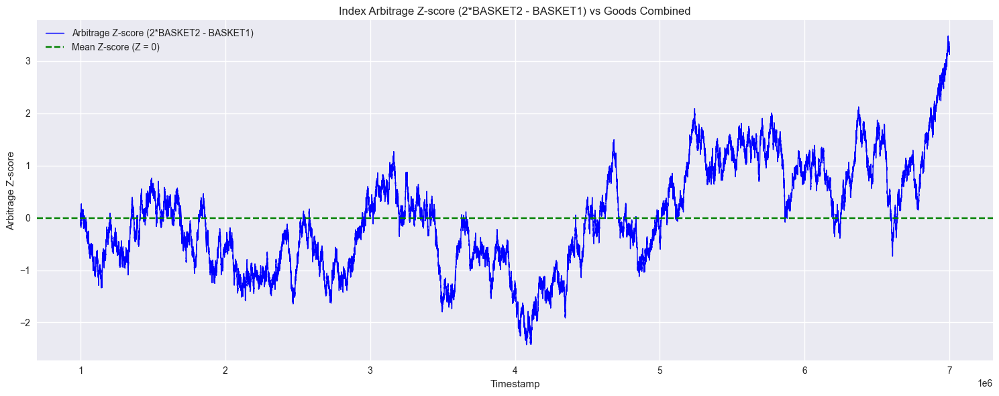

In [ ]:
#"Index Arbitrage Z-score (2*BASKET2 - BASKET1) vs Goods Combined"

import pandas as pd
import matplotlib.pyplot as plt



# Step 2: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 3: Merge all into one DataFrame on timestamp
merged_df = picnic2_df.merge(picnic1_df, on='timestamp', how='inner') \
                      .merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Step 4: Compute synthetic price and spread
merged_df['arbitrage_spread'] = (
    2 * merged_df['picnic2'] -
    1 * merged_df['picnic1'] -
    2 * merged_df['croissant'] -
    1 * merged_df['jams'] +
    1 * merged_df['djembes']
)

# Step 5: Compute Z-score for the arbitrage spread
mean_spread = merged_df['arbitrage_spread'].mean()
std_spread = merged_df['arbitrage_spread'].std()
merged_df['arbitrage_zscore'] = (merged_df['arbitrage_spread'] - mean_spread) / std_spread

# Step 6: Plot arbitrage Z-score and mean Z-score line
plt.figure(figsize=(15, 6))

plt.plot(merged_df['timestamp'], merged_df['arbitrage_zscore'], label='Arbitrage Z-score (2*BASKET2 - BASKET1)', color='blue', linewidth=1)

# Draw mean Z-score as dashed horizontal line (Z = 0)
plt.axhline(y=0, color='green', linestyle='--', label='Mean Z-score (Z = 0)')

plt.title("Index Arbitrage Z-score (2*BASKET2 - BASKET1) vs Goods Combined")
plt.xlabel("Timestamp")
plt.ylabel("Arbitrage Z-score")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Arbitrage Spread (-3ASKET2 +2BASKET1) Mean: -148.89886666666666
Arbitrage Spread (Croissant -Jam) Mean: -2257.9628583333333
OLD :Arbitrage Spread (-3ASKET2 +2BASKET1) Mean: -76.43472Arbitrage Spread (Croissant -Jam) Mean: -2275.958


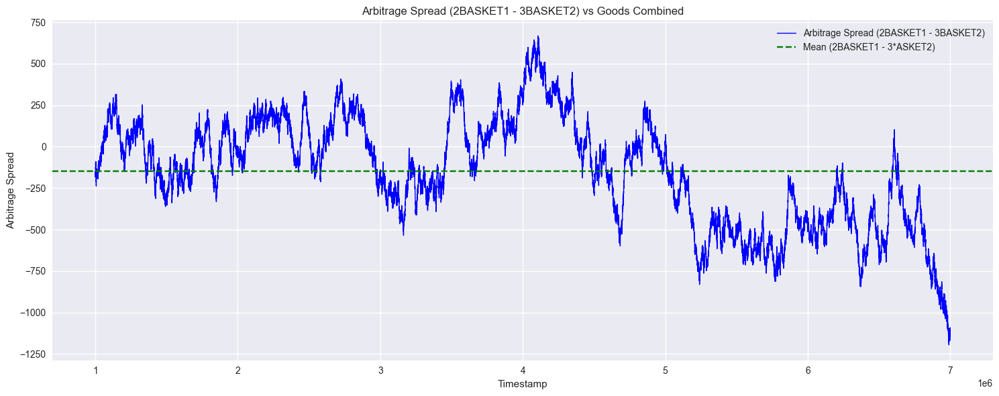

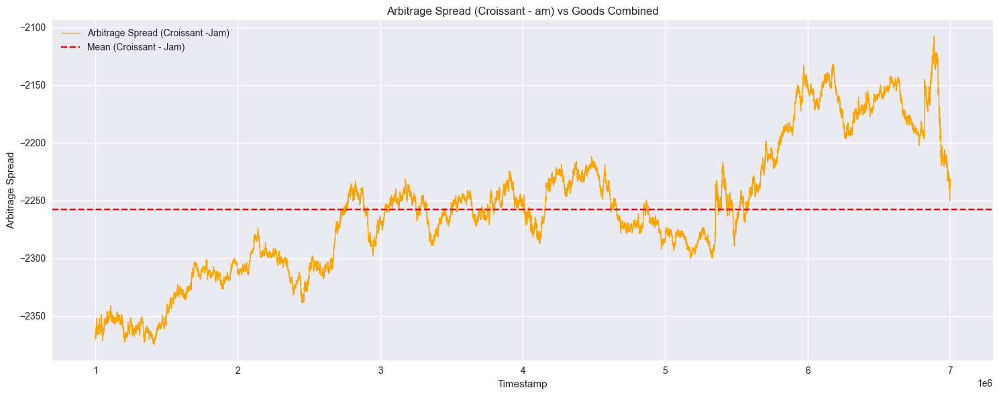

In [ ]:
#Arbitrage Spread (2BASKET1 - 3BASKET2) vs Goods Combined

import pandas as pd
import matplotlib.pyplot as plt



# Step 2: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 3: Merge all into one DataFrame on timestamp
merged_df = picnic2_df.merge(picnic1_df, on='timestamp', how='inner') \
                      .merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Formula 1: Calculate Arbitrage Spread for 2*BASKET2 - 3*BASKET1 = 2*DJEMBE
merged_df['arbitrage_spread_basket1'] = (
    - 3 * merged_df['picnic2'] +
    2 * merged_df['picnic1'] -
    2 * merged_df['djembes']
)

# Formula 2: Correct Arbitrage Spread for Croissant + Jam (no multiplier for Croissant)
merged_df['arbitrage_spread_croissant_jam'] = (
    1 * merged_df['croissant'] - 
    1 * merged_df['jams']
)

# Step 5: Compute and print overall arbitrage spread means for both formulas
arbitrage_spread_basket1_mean = merged_df['arbitrage_spread_basket1'].mean()
arbitrage_spread_croissant_jam_mean = merged_df['arbitrage_spread_croissant_jam'].mean()

print("Arbitrage Spread (-3ASKET2 +2BASKET1) Mean:", arbitrage_spread_basket1_mean)
print("Arbitrage Spread (Croissant -Jam) Mean:", arbitrage_spread_croissant_jam_mean)
print(
    "OLD :"
    "Arbitrage Spread (-3ASKET2 +2BASKET1) Mean: -76.43472"
    "Arbitrage Spread (Croissant -Jam) Mean: -2275.958"
)

# Step 6: Plot 1 - Arbitrage Spread (2*BASKET2 - 3*BASKET1)
plt.figure(figsize=(15, 6))

# Plot Arbitrage Spread (2*BASKET2 - 3*BASKET1)
plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread_basket1'], label='Arbitrage Spread (2BASKET1 - 3BASKET2)', color='blue', linewidth=1)
plt.axhline(y=arbitrage_spread_basket1_mean, color='green', linestyle='--', label='Mean (2BASKET1 - 3*ASKET2)')

plt.title("Arbitrage Spread (2BASKET1 - 3BASKET2) vs Goods Combined")
plt.xlabel("Timestamp")
plt.ylabel("Arbitrage Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Step 7: Plot 2 - Arbitrage Spread (Croissant + Jam)
plt.figure(figsize=(15, 6))

# Plot Arbitrage Spread (Croissant + Jam)
plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread_croissant_jam'], label='Arbitrage Spread (Croissant -Jam)', color='orange', linewidth=1)
plt.axhline(y=arbitrage_spread_croissant_jam_mean, color='red', linestyle='--', label='Mean (Croissant - Jam)')

plt.title("Arbitrage Spread (Croissant - am) vs Goods Combined")
plt.xlabel("Timestamp")
plt.ylabel("Arbitrage Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

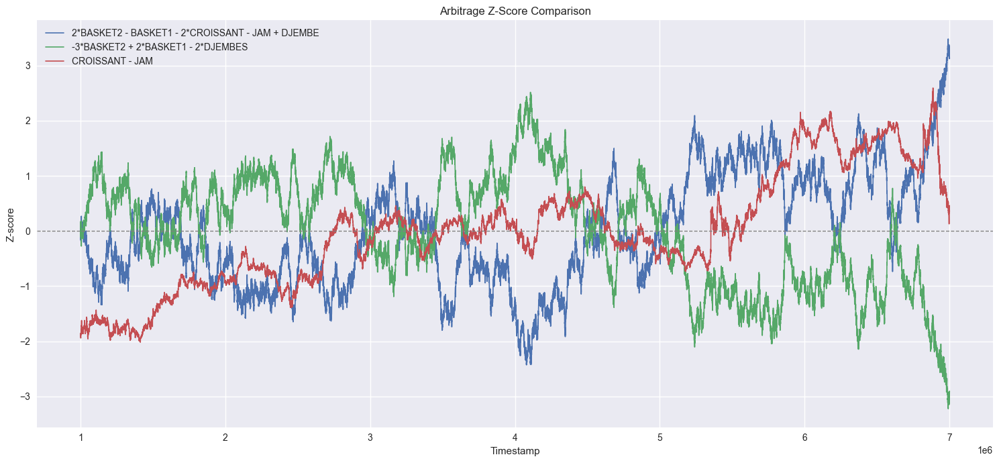

In [ ]:
#z SCORES

import pandas as pd
import matplotlib.pyplot as plt



# Step 2: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 3: Merge all into one DataFrame on timestamp
merged_df = picnic2_df.merge(picnic1_df, on='timestamp', how='inner') \
                      .merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Step 4a: Original Arbitrage Spread (combined goods vs baskets)
merged_df['arbitrage_spread'] = (
    2 * merged_df['picnic2'] -
    1 * merged_df['picnic1'] -
    2 * merged_df['croissant'] -
    1 * merged_df['jams'] +
    1 * merged_df['djembes']
)

# Step 4b: Arbitrage Spread between baskets
merged_df['arbitrage_spread_basket1'] = (
    - 3 * merged_df['picnic2'] +
    2 * merged_df['picnic1'] -
    2 * merged_df['djembes']
)

# Step 4c: Arbitrage between Croissant and Jam
merged_df['arbitrage_spread_croissant_jam'] = (
    merged_df['croissant'] - merged_df['jams']
)

# Step 5: Z-scores
for col in ['arbitrage_spread', 'arbitrage_spread_basket1', 'arbitrage_spread_croissant_jam']:
    z_col = col + '_zscore'
    mean = merged_df[col].mean()
    std = merged_df[col].std()
    merged_df[z_col] = (merged_df[col] - mean) / std

# Step 6: Plot all Z-scores together
plt.figure(figsize=(15, 7))
plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread_zscore'], label='2*BASKET2 - BASKET1 - 2*CROISSANT - JAM + DJEMBE', linewidth=1.2)
plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread_basket1_zscore'], label='-3*BASKET2 + 2*BASKET1 - 2*DJEMBES', linewidth=1.2)
plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread_croissant_jam_zscore'], label='CROISSANT - JAM', linewidth=1.2)

plt.axhline(y=0, color='gray', linestyle='--', linewidth=1)
plt.title("Arbitrage Z-Score Comparison")
plt.xlabel("Timestamp")
plt.ylabel("Z-score")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
merged_df['z_score'] = (merged_df['spread'] - merged_df['spread_ma']) / merged_df['spread_std']

# === Create a figure with secondary y-axis ===
fig = make_subplots(specs=[[{"secondary_y": True}]])

# === Primary Y-axis: Spread and its Moving Average ===
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread'],
    mode='lines', name='Spread',
    line=dict(color='darkorange'),
    opacity=0.8  # Adding some transparency to spread
), secondary_y=False)

fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['spread_ma'],
    mode='lines', name=f'{spread_window}-period MA',
    line=dict(color='blue'),
    opacity=0.8  # Adding some transparency to MA
), secondary_y=False)

# === Secondary Y-axis: Z-score with higher opacity ===
fig.add_trace(go.Scatter(
    x=merged_df['timestamp'], y=merged_df['z_score'],
    mode='lines', name='Z-Score',
    line=dict(color='purple', width=2.5),
    opacity=0.3  # Reduced opacity for Z-score as per your example
), secondary_y=True)

# Add horizontal thresholds for Z-score on the secondary y-axis
fig.add_hline(y=2, line_dash="dash", line_color="green", secondary_y=True, opacity=0.7)
fig.add_hline(y=-2, line_dash="dash", line_color="red", secondary_y=True, opacity=0.7)
fig.add_hline(y=0, line_dash="dot", line_color="gray", secondary_y=True, opacity=0.5)

# === Update layout ===
fig.update_layout(
    height=800,
    width=1600,
    title="Superposed Spread & Z-Score Between SQUID_INK and KELP",
    showlegend=True,
    template='plotly_white',
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

# Calculate Z-score range for fixed axis scaling
z_min = merged_df['z_score'].min()
z_max = merged_df['z_score'].max()
# Add some padding to the range (10%)
z_padding = (z_max - z_min) * 0.1
z_range = [z_min - z_padding, z_max + z_padding]

# Set y-axes titles and fix scaling for Z-score axis
fig.update_yaxes(title_text="Spread", secondary_y=False)
fig.update_yaxes(
    title_text="Z-Score", 
    secondary_y=True,
    range=z_range,  # Set fixed range for Z-score
    fixedrange=False,  # Allow zooming but will maintain proper scale
    showgrid=True,     # Show grid lines for Z-score axis
    gridcolor='rgba(128, 0, 128, 0.1)',  # Light purple grid to match Z-score line
    zeroline=True,     # Show zero line
    zerolinewidth=1.5,
    zerolinecolor='rgba(128, 0, 128, 0.3)'
)

# Add a light background color to the secondary y-axis area to visually distinguish it
fig.update_layout(
    plot_bgcolor='rgba(240,240,240,0.95)'
)

# Ensure proper scales are maintained when zooming on data
fig.update_layout(
    xaxis=dict(
        domain=[0.0, 0.94]  # Give slightly more space for the secondary y-axis
    )
)

fig.show()

In [ ]:
window = 40
# Assuming ink_df is already defined with the calculations as in your code:
# ink_df['mid_price'] = (ink_df['ask_price_1'] + ink_df['bid_price_1']) / 2
ink_df['ma'] = ink_df['mid_price'].rolling(window).mean()
# ink_df['std'] = ink_df['mid_price'].rolling(window).std()
# ink_df['z_score'] = (ink_df['mid_price'] - ink_df['ma']) / ink_df['std']

# Calculate Z-score change (first derivative)
ink_df['z_score_change'] = ink_df['z_score'].diff()
# Smooth with rolling mean
ink_df['z_score_change_smooth'] = ink_df['z_score_change'].rolling(3).mean()

# Create a figure with secondary y-axis
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Primary Y-axis: Mid Price and Moving Average
fig.add_trace(go.Scatter(
    x=ink_df['timestamp'], 
    y=ink_df['mid_price'],
    mode='lines', 
    name='Mid Price',
    line=dict(color='blue', width=2),
    opacity=0.9
), secondary_y=False)

fig.add_trace(go.Scatter(
    x=ink_df['timestamp'], 
    y=ink_df['ma'],
    mode='lines', 
    name=f'{window}-period MA',
    line=dict(color='darkorange', width=1.5),
    opacity=0.8
), secondary_y=False)

# Secondary Y-axis: Z-score Change (raw)
fig.add_trace(go.Scatter(
    x=ink_df['timestamp'], 
    y=ink_df['z_score_change'],
    mode='lines', 
    name='Z-Score Change',
    line=dict(color='purple', width=1, dash='dot'),
    opacity=0.3
), secondary_y=True)

# Secondary Y-axis: Z-score Change (smoothed)
fig.add_trace(go.Scatter(
    x=ink_df['timestamp'], 
    y=ink_df['z_score_change_smooth'],
    mode='lines', 
    name='Z-Score Change (Smoothed)',
    line=dict(color='green', width=1.5),
    opacity=0.7
), secondary_y=True)

# Add horizontal threshold at zero for Z-score change
fig.add_hline(y=0, line_dash="dash", line_color="gray", secondary_y=True, opacity=0.6)

# Calculate Z-score change range for fixed axis scaling
z_change_min = min(ink_df['z_score_change'].min(), ink_df['z_score_change_smooth'].min())
z_change_max = max(ink_df['z_score_change'].max(), ink_df['z_score_change_smooth'].max())
z_change_padding = (z_change_max - z_change_min) * 0.1
z_change_range = [z_change_min - z_change_padding, z_change_max + z_change_padding]

# Update layout
fig.update_layout(
    height=800,
    width=1600,
    title="SQUID_INK: Mid Price with Z-Score Change Overlay",
    showlegend=True,
    template='plotly_white',
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    grid=dict(rows=1, columns=1),
    plot_bgcolor='rgba(240,240,240,0.95)'
)

# Set y-axes titles
fig.update_yaxes(
    title_text="Mid Price", 
    secondary_y=False,
    titlefont=dict(color='blue'),
    tickfont=dict(color='blue')
)

fig.update_yaxes(
    title_text="Z-Score Change", 
    secondary_y=True,
    range=z_change_range,
    fixedrange=False,
    showgrid=True,
    gridcolor='rgba(128, 128, 128, 0.1)',
    zeroline=True,
    zerolinewidth=1.5,
    zerolinecolor='rgba(128, 128, 128, 0.4)',
    titlefont=dict(color='green'),
    tickfont=dict(color='green')
)

# Ensure proper scales are maintained when zooming on data
fig.update_layout(
    xaxis=dict(
        domain=[0.0, 0.94]
    )
)

fig.show()


--- Analyzing PICNIC_BASKET1 ---
Spread mean over all days: 5.2518, Std Dev: 112.9758
At timestamp 0: Mean = nan, Std Dev = nan
At timestamp 1000000: Mean = 0.0000, Std Dev = nan
At timestamp 2000000: Mean = 70.0289, Std Dev = 78.6794
At timestamp 3000000: Mean = 56.9822, Std Dev = 81.7867
At timestamp 4000000: Mean = 48.7653, Std Dev = 85.1195
At timestamp 5000000: Mean = 60.7451, Std Dev = 86.2200
At timestamp 6000000: Mean = 29.2654, Std Dev = 104.8266
At timestamp 7000000: Mean = 5.2518, Std Dev = 112.9758
Average of spread means at timestamps: 38.7198
Average of spread std devs at timestamps: 91.6014


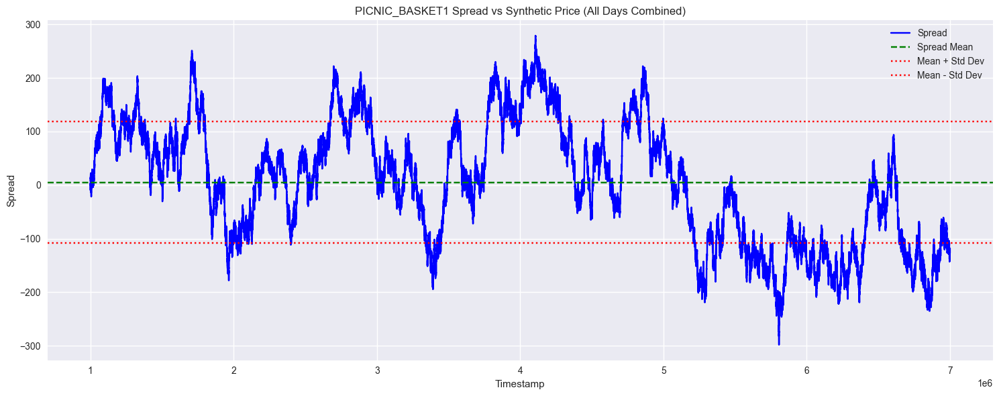


--- Analyzing PICNIC_BASKET2 ---
Spread mean over all days: 53.1341, Std Dev: 66.0521
At timestamp 0: Mean = nan, Std Dev = nan
At timestamp 1000000: Mean = 50.0000, Std Dev = nan
At timestamp 2000000: Mean = 58.0698, Std Dev = 51.8931
At timestamp 3000000: Mean = 27.1227, Std Dev = 61.8341
At timestamp 4000000: Mean = 30.2348, Std Dev = 59.8485
At timestamp 5000000: Mean = 31.4479, Std Dev = 58.5253
At timestamp 6000000: Mean = 44.9911, Std Dev = 60.8118
At timestamp 7000000: Mean = 53.1341, Std Dev = 66.0521
Average of spread means at timestamps: 42.1429
Average of spread std devs at timestamps: 59.8275


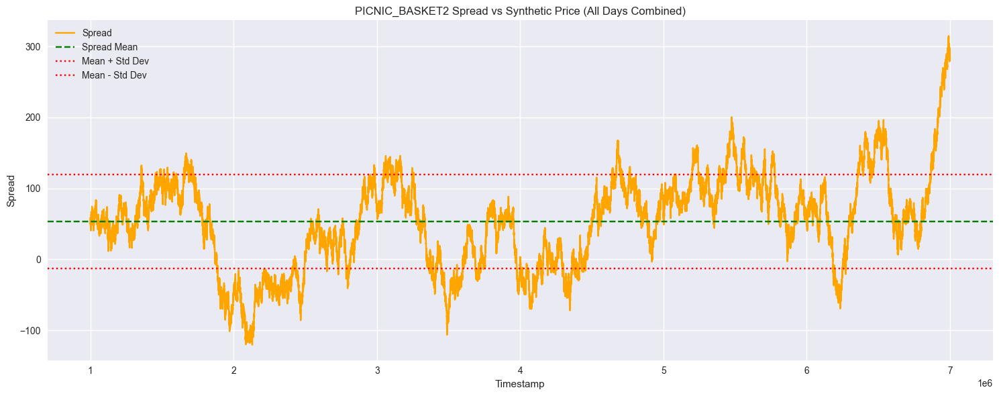

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def analyze_basket(df, basket_name, weights, timestamps_to_check, color='blue'):
    print(f"\n--- Analyzing {basket_name} ---")

    # Filter and rename
    basket_df = df.loc[df['product'] == basket_name, ['timestamp', 'mid_price']].rename(columns={'mid_price': 'basket'})
    croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
    djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
    jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

    # Merge
    merged_df = basket_df.merge(croissant_df, on='timestamp', how='inner') \
                         .merge(djembes_df, on='timestamp', how='inner') \
                         .merge(jams_df, on='timestamp', how='inner') \
                         .dropna()

    # Synthetic & spread
    merged_df['synthetic'] = (
        weights['CROISSANTS'] * merged_df['croissant'] +
        weights['DJEMBES'] * merged_df['djembes'] +
        weights['JAMS'] * merged_df['jams']
    )
    merged_df['spread'] = merged_df['basket'] - merged_df['synthetic']

    # Overall stats
    spread_mean = merged_df['spread'].mean()
    spread_std = merged_df['spread'].std()
    print(f"Spread mean over all days: {spread_mean:.4f}, Std Dev: {spread_std:.4f}")

    # Per-timestamp stats
    means = []
    stds = []
    for timestamp in timestamps_to_check:
        snapshot = merged_df[merged_df['timestamp'] <= timestamp]
        mean_at_timestamp = snapshot['spread'].mean()
        std_at_timestamp = snapshot['spread'].std()
        if not pd.isna(mean_at_timestamp):
            means.append(mean_at_timestamp)
        if not pd.isna(std_at_timestamp):
            stds.append(std_at_timestamp)
        print(f"At timestamp {timestamp}: Mean = {mean_at_timestamp:.4f}, Std Dev = {std_at_timestamp:.4f}")

    # Averages of means and stds
    if means:
        overall_avg_mean = sum(means) / len(means)
        print(f"Average of spread means at timestamps: {overall_avg_mean:.4f}")
    else:
        print("No valid spread means to average.")

    if stds:
        overall_avg_std = sum(stds) / len(stds)
        print(f"Average of spread std devs at timestamps: {overall_avg_std:.4f}")
    else:
        print("No valid spread std devs to average.")

    # Plot
    plt.figure(figsize=(15, 6))
    plt.plot(merged_df['timestamp'], merged_df['spread'], label='Spread', color=color)
    plt.axhline(y=spread_mean, color='green', linestyle='--', label='Spread Mean')
    plt.axhline(y=spread_mean + spread_std, color='red', linestyle=':', label='Mean + Std Dev')
    plt.axhline(y=spread_mean - spread_std, color='red', linestyle=':', label='Mean - Std Dev')
    plt.title(f"{basket_name} Spread vs Synthetic Price (All Days Combined)")
    plt.xlabel("Timestamp")
    plt.ylabel("Spread")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ----- MAIN EXECUTION -----
timestamps_to_check = [0, 1_000_000, 2_000_000, 3_000_000, 4_000_000, 5_000_000, 6_000_000, 7_000_000]

# Analyze each basket
analyze_basket(
    df,
    basket_name='PICNIC_BASKET1',
    weights={'CROISSANTS': 6, 'DJEMBES': 1, 'JAMS': 3},
    timestamps_to_check=timestamps_to_check,
    color='blue'
)

analyze_basket(
    df,
    basket_name='PICNIC_BASKET2',
    weights={'CROISSANTS': 4, 'DJEMBES': 0, 'JAMS': 2},
    timestamps_to_check=timestamps_to_check,
    color='orange'
)



Arbitrage Spread (2*BASKET1 - 3*BASKET2 - 2*DJEMBES) Overall Mean: -148.8989, Std Dev: 324.5735
At timestamp 1000000: Mean = -150.0000, Std Dev = nan
At timestamp 2000000: Mean = -34.1516, Std Dev = 146.8185
At timestamp 3000000: Mean = 32.5963, Std Dev = 157.8522
At timestamp 4000000: Mean = 6.8263, Std Dev = 187.0152
At timestamp 5000000: Mean = 27.1466, Std Dev = 212.5402
At timestamp 6000000: Mean = -76.4426, Std Dev = 291.4268
At timestamp 7000000: Mean = -148.8989, Std Dev = 324.5735

Average of spread means at timestamps: -48.9891
Average of spread std devs at timestamps: 220.0377


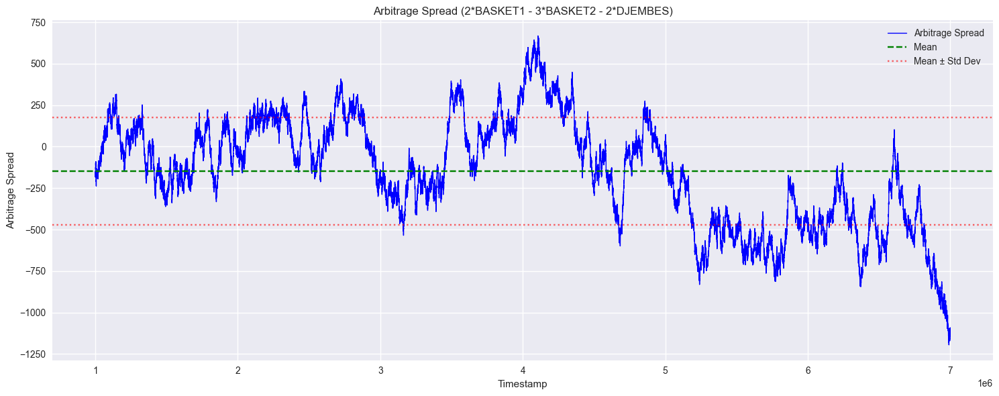

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 2: Merge all into one DataFrame on timestamp
merged_df = picnic2_df.merge(picnic1_df, on='timestamp', how='inner') \
                      .merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Step 3: Calculate Arbitrage Spread for 2*BASKET1 - 3*BASKET2 - 2*DJEMBE
merged_df['arbitrage_spread'] = (
    2 * merged_df['picnic1']
    - 3 * merged_df['picnic2']
    - 2 * merged_df['djembes']
)

# Step 4: Compute overall mean and std dev
spread_mean = merged_df['arbitrage_spread'].mean()
spread_std = merged_df['arbitrage_spread'].std()
print(f"\nArbitrage Spread (2*BASKET1 - 3*BASKET2 - 2*DJEMBES) Overall Mean: {spread_mean:.4f}, Std Dev: {spread_std:.4f}")

# Step 5: Analyze at specific timestamps
timestamps_to_check = [1_000_000, 2_000_000, 3_000_000, 4_000_000, 5_000_000, 6_000_000, 7_000_000]
means = []
stds = []

for timestamp in timestamps_to_check:
    snapshot = merged_df[merged_df['timestamp'] <= timestamp]
    mean_at_timestamp = snapshot['arbitrage_spread'].mean()
    std_at_timestamp = snapshot['arbitrage_spread'].std()
    
    if not pd.isna(mean_at_timestamp):
        means.append(mean_at_timestamp)
    if not pd.isna(std_at_timestamp):
        stds.append(std_at_timestamp)
        
    print(f"At timestamp {timestamp}: Mean = {mean_at_timestamp:.4f}, Std Dev = {std_at_timestamp:.4f}")

# Step 6: Average of means and stds across timestamps
if means:
    avg_of_means = sum(means) / len(means)
    print(f"\nAverage of spread means at timestamps: {avg_of_means:.4f}")
else:
    print("\nNo valid spread means to average.")

if stds:
    avg_of_stds = sum(stds) / len(stds)
    print(f"Average of spread std devs at timestamps: {avg_of_stds:.4f}")
else:
    print("No valid spread std devs to average.")

# Step 7: Plot spread and bounds
plt.figure(figsize=(15, 6))
plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread'], label='Arbitrage Spread', color='blue', linewidth=1)
plt.axhline(y=spread_mean, color='green', linestyle='--', label='Mean')
plt.axhline(y=spread_mean + spread_std, color='red', linestyle=':', alpha=0.6, label='Mean ± Std Dev')
plt.axhline(y=spread_mean - spread_std, color='red', linestyle=':', alpha=0.6)

plt.title("Arbitrage Spread (2*BASKET1 - 3*BASKET2 - 2*DJEMBES)")
plt.xlabel("Timestamp")
plt.ylabel("Arbitrage Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


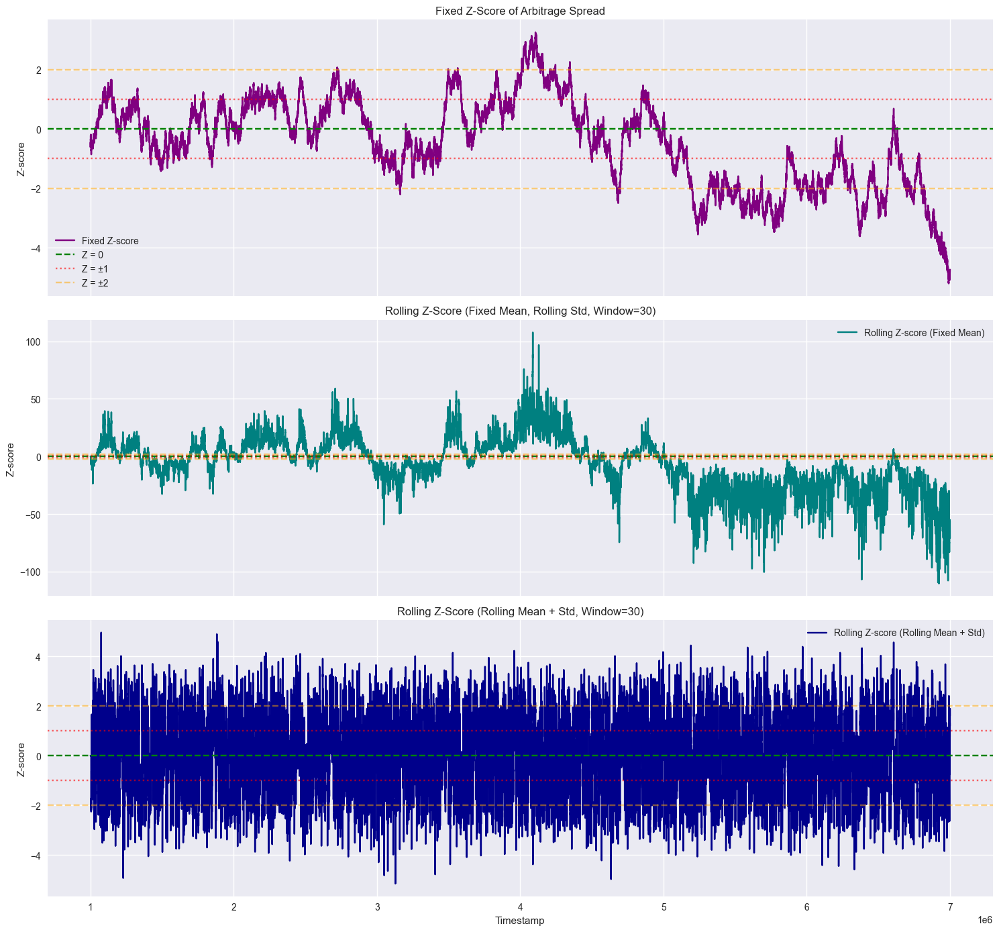

In [34]:
#import statistics

# Step 1: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 2: Merge all into one DataFrame on timestamp
merged_df = picnic2_df.merge(picnic1_df, on='timestamp', how='inner') \
                      .merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Step 3: Calculate Arbitrage Spread for 2*BASKET1 - 3*BASKET2 - 2*DJEMBE
merged_df['arbitrage_spread'] = (
    2 * merged_df['picnic1']
    - 3 * merged_df['picnic2']
    - 2 * merged_df['djembes']
)

# Step 4: Fixed Z-score using constant mean/stdev
fixed_mean = -48.9891
fixed_stdev = 220.0377
merged_df['fixed_z_score'] = merged_df['arbitrage_spread'].apply(
    lambda spread: (spread - fixed_mean) / fixed_stdev if fixed_stdev > 0 else spread - fixed_mean
)

# Step 5: Rolling Z-score (fixed mean, rolling stdev)
spread_history = []
rolling_z_scores_fixed_mean = []

for spread in merged_df['arbitrage_spread']:
    spread_history.append(spread)
    if len(spread_history) > 30:
        spread_history.pop(0)
        stdev = statistics.stdev(spread_history)
        z = (spread - fixed_mean) / stdev if stdev > 0 else 0
    else:
        z = 0
    rolling_z_scores_fixed_mean.append(z)

merged_df['rolling_z_score_fixed_mean'] = rolling_z_scores_fixed_mean

# Step 6: Rolling Z-score with rolling mean + rolling stdev
rolling_z_scores_dynamic = []
rolling_window = 50

for i in range(len(merged_df)):
    if i >= rolling_window:
        window_data = merged_df['arbitrage_spread'].iloc[i - rolling_window:i]
        roll_mean = window_data.mean()
        roll_std = window_data.std()
        z = (merged_df['arbitrage_spread'].iloc[i] - roll_mean) / roll_std if roll_std > 0 else 0
    else:
        z = 0
    rolling_z_scores_dynamic.append(z)

merged_df['rolling_z_score_dynamic'] = rolling_z_scores_dynamic

# Step 7: Plot all three Z-scores
fig, axs = plt.subplots(3, 1, figsize=(15, 14), sharex=True)

# Plot 1: Fixed Z-score
axs[0].plot(merged_df['timestamp'], merged_df['fixed_z_score'], label='Fixed Z-score', color='purple')
axs[0].axhline(y=0, color='green', linestyle='--', label='Z = 0')
axs[0].axhline(y=1, color='red', linestyle=':', alpha=0.6, label='Z = ±1')
axs[0].axhline(y=-1, color='red', linestyle=':', alpha=0.6)
axs[0].axhline(y=2, color='orange', linestyle='--', alpha=0.5, label='Z = ±2')
axs[0].axhline(y=-2, color='orange', linestyle='--', alpha=0.5)
axs[0].set_title("Fixed Z-Score of Arbitrage Spread")
axs[0].set_ylabel("Z-score")
axs[0].legend()
axs[0].grid(True)

# Plot 2: Rolling Stdev Only
axs[1].plot(merged_df['timestamp'], merged_df['rolling_z_score_fixed_mean'], label='Rolling Z-score (Fixed Mean)', color='teal')
axs[1].axhline(y=0, color='green', linestyle='--')
axs[1].axhline(y=1, color='red', linestyle=':', alpha=0.6)
axs[1].axhline(y=-1, color='red', linestyle=':', alpha=0.6)
axs[1].axhline(y=2, color='orange', linestyle='--', alpha=0.5)
axs[1].axhline(y=-2, color='orange', linestyle='--', alpha=0.5)
axs[1].set_title("Rolling Z-Score (Fixed Mean, Rolling Std, Window=30)")
axs[1].set_ylabel("Z-score")
axs[1].legend()
axs[1].grid(True)

# Plot 3: Rolling Mean and Std
axs[2].plot(merged_df['timestamp'], merged_df['rolling_z_score_dynamic'], label='Rolling Z-score (Rolling Mean + Std)', color='darkblue')
axs[2].axhline(y=0, color='green', linestyle='--')
axs[2].axhline(y=1, color='red', linestyle=':', alpha=0.6)
axs[2].axhline(y=-1, color='red', linestyle=':', alpha=0.6)
axs[2].axhline(y=2, color='orange', linestyle='--', alpha=0.5)
axs[2].axhline(y=-2, color='orange', linestyle='--', alpha=0.5)
axs[2].set_title("Rolling Z-Score (Rolling Mean + Std, Window=30)")
axs[2].set_xlabel("Timestamp")
axs[2].set_ylabel("Z-score")
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()



Arbitrage Spread Mean over all days: 101.0165, Std Dev: 187.6815
At timestamp 1000000: Mean = 100.0000, Std Dev = nan
At timestamp 2000000: Mean = 46.1107, Std Dev = 88.4004
At timestamp 3000000: Mean = -2.7368, Std Dev = 99.4964
At timestamp 4000000: Mean = 11.7043, Std Dev = 113.2473
At timestamp 5000000: Mean = 2.1506, Std Dev = 126.5109
At timestamp 6000000: Mean = 60.7169, Std Dev = 168.3599
At timestamp 7000000: Mean = 101.0165, Std Dev = 187.6815

Average of spread means at timestamps: 45.5660
Average of spread std devs at timestamps: 130.6161


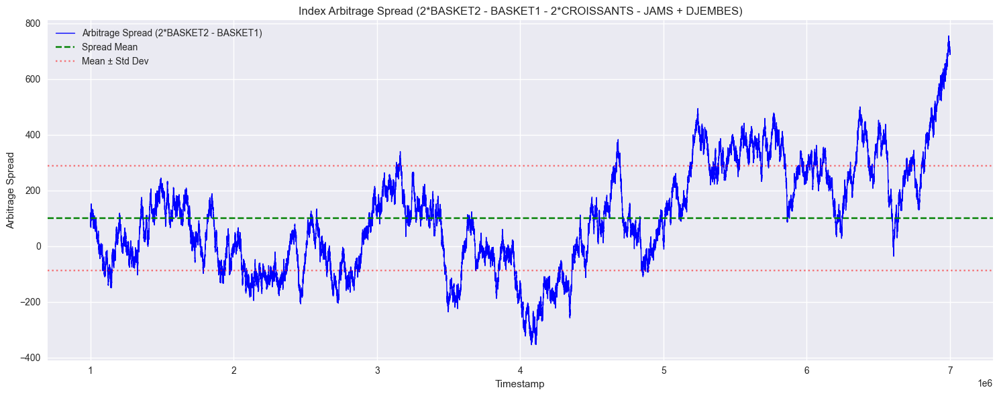

In [5]:
import pandas as pd
import matplotlib.pyplot as plt


# Step 1: Filter and rename columns per product
picnic2_df = df.loc[df['product'] == 'PICNIC_BASKET2', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic2'})
picnic1_df = df.loc[df['product'] == 'PICNIC_BASKET1', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'picnic1'})
croissant_df = df.loc[df['product'] == 'CROISSANTS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'croissant'})
djembes_df = df.loc[df['product'] == 'DJEMBES', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'djembes'})
jams_df = df.loc[df['product'] == 'JAMS', ['timestamp', 'mid_price']].rename(columns={'mid_price': 'jams'})

# Step 2: Merge all dataframes on timestamp
merged_df = picnic2_df.merge(picnic1_df, on='timestamp', how='inner') \
                      .merge(croissant_df, on='timestamp', how='inner') \
                      .merge(djembes_df, on='timestamp', how='inner') \
                      .merge(jams_df, on='timestamp', how='inner') \
                      .dropna()

# Step 3: Compute synthetic spread
merged_df['arbitrage_spread'] = (
    2 * merged_df['picnic2']
    - merged_df['picnic1']
    - 2 * merged_df['croissant']
    - merged_df['jams']
    + merged_df['djembes']
)

# Step 4: Compute and print overall mean and std
spread_mean = merged_df['arbitrage_spread'].mean()
spread_std = merged_df['arbitrage_spread'].std()
print(f"\nArbitrage Spread Mean over all days: {spread_mean:.4f}, Std Dev: {spread_std:.4f}")

# Step 5: Per-timestamp analysis
timestamps_to_check = [1_000_000, 2_000_000, 3_000_000, 4_000_000, 5_000_000, 6_000_000,7_000_000]
means = []
stds = []

for timestamp in timestamps_to_check:
    snapshot = merged_df[merged_df['timestamp'] <= timestamp]
    mean_at_timestamp = snapshot['arbitrage_spread'].mean()
    std_at_timestamp = snapshot['arbitrage_spread'].std()
    if not pd.isna(mean_at_timestamp):
        means.append(mean_at_timestamp)
    if not pd.isna(std_at_timestamp):
        stds.append(std_at_timestamp)
    print(f"At timestamp {timestamp}: Mean = {mean_at_timestamp:.4f}, Std Dev = {std_at_timestamp:.4f}")

# Step 6: Averages of timestamp means and stds
if means:
    avg_of_means = sum(means) / len(means)
    print(f"\nAverage of spread means at timestamps: {avg_of_means:.4f}")
else:
    print("\nNo valid spread means to average.")

if stds:
    avg_of_stds = sum(stds) / len(stds)
    print(f"Average of spread std devs at timestamps: {avg_of_stds:.4f}")
else:
    print("No valid spread std devs to average.")

# Step 7: Plot
plt.figure(figsize=(15, 6))
plt.plot(merged_df['timestamp'], merged_df['arbitrage_spread'], label='Arbitrage Spread (2*BASKET2 - BASKET1)', color='blue', linewidth=1)
plt.axhline(y=spread_mean, color='green', linestyle='--', label='Spread Mean')
plt.axhline(y=spread_mean + spread_std, color='red', linestyle=':', alpha=0.5, label='Mean ± Std Dev')
plt.axhline(y=spread_mean - spread_std, color='red', linestyle=':', alpha=0.5)

plt.title("Index Arbitrage Spread (2*BASKET2 - BASKET1 - 2*CROISSANTS - JAMS + DJEMBES)")
plt.xlabel("Timestamp")
plt.ylabel("Arbitrage Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [3]:
import pandas as pd
import statsmodels.api as sm

# === Timestamp offsets ===
price_day_offsets = {
    "../data/prices_round_1_day_-2.csv": 0,
    "../data/prices_round_2_day_-1.csv": 1_000_000,
    "../data/prices_round_3_day_0.csv": 2_000_000,
    "../data/prices_round_4_day_1.csv": 3_000_000,
    "../data/prices_round_5_day_2.csv": 4_000_000,
    "../data/prices_round_5_day_3.csv": 5_000_000,
    "../data/prices_round_5_day_4.csv": 6_000_000,
}

obs_day_offsets = {
    "../data/observations_round_4_day_1.csv": 3_000_000,
    "../data/observations_round_4_day_2.csv": 4_000_000,
    "../data/observations_round_4_day_3.csv": 5_000_000,
    "../data/observations_round_5_day_2.csv": 4_000_000,
    "../data/observations_round_5_day_3.csv": 5_000_000,
    "../data/observations_round_5_day_4.csv": 6_000_000,
}

# === Load & preprocess price data ===
price_files = list(price_day_offsets.keys())
dfs = []

for file in price_files:
    df = pd.read_csv(f"Prices/{file}")
    df = df.iloc[:, 0].str.split(";", expand=True)
    df.columns = [
        "day", "timestamp", "product",
        "bid_price_1", "bid_volume_1", "bid_price_2", "bid_volume_2", "bid_price_3", "bid_volume_3",
        "ask_price_1", "ask_volume_1", "ask_price_2", "ask_volume_2", "ask_price_3", "ask_volume_3",
        "mid_price", "profit_and_loss"
    ]
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce") + price_day_offsets[file]
    numeric_cols = df.columns.difference(["day", "timestamp", "product"])
    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
    dfs.append(df)

price_df = pd.concat(dfs, ignore_index=True)
mac_df = price_df[price_df["product"] == "MAGNIFICENT_MACARONS"]
mac_df = mac_df[["timestamp", "mid_price"]].dropna()

# === Load & preprocess observation data ===
obs_files = list(obs_day_offsets.keys())
obs_dfs = []

for file in obs_files:
    df = pd.read_csv(f"Prices/{file}")
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce") + obs_day_offsets[file]
    df = df[["timestamp", "sugarPrice", "sunlightIndex"]]
    obs_dfs.append(df)

obs_df = pd.concat(obs_dfs, ignore_index=True)

# === Merge datasets ===
merged = pd.merge(mac_df, obs_df, on="timestamp").dropna()

# === Filter only when sunlightIndex < 44 ===
filtered = merged[merged["sunlightIndex"] < 44]

# === Regression: mid_price ~ sugarPrice only ===
X = filtered[["sugarPrice"]]
X = sm.add_constant(X)
y = filtered["mid_price"]

model = sm.OLS(y, X).fit()
print(model.summary())

# === Print usable values for your bot ===
a = model.params["sugarPrice"]
c = model.params["const"]
print(f"\n→ fair_value = {a:.4f} * sugarPrice + {c:.4f}")


                            OLS Regression Results                            
Dep. Variable:              mid_price   R-squared:                       0.670
Model:                            OLS   Adj. R-squared:                  0.670
Method:                 Least Squares   F-statistic:                 1.898e+04
Date:                Mon, 21 Apr 2025   Prob (F-statistic):               0.00
Time:                        13:47:58   Log-Likelihood:                -49236.
No. Observations:                9331   AIC:                         9.848e+04
Df Residuals:                    9329   BIC:                         9.849e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -872.1104     12.100    -72.074      0.0

In [ ]:



# === Define timestamp offsets for each day ===
price_day_offsets = {
    "../data/prices_round_1_day_-2.csv": 0,
    "../data/prices_round_2_day_-1.csv": 1_000_000,
    "../data/prices_round_3_day_0.csv": 2_000_000,
    "../data/prices_round_4_day_1.csv": 3_000_000,
    "../data/prices_round_5_day_2.csv": 4_000_000,
    "../data/prices_round_5_day_3.csv": 5_000_000,
    "../data/prices_round_5_day_4.csv": 6_000_000,
}

obs_day_offsets = {
    "../data/observations_round_4_day_1.csv": 3_000_000,
    "../data/observations_round_4_day_2.csv": 3_000_000 + 1_000_000,
    "../data/observations_round_4_day_3.csv": 3_000_000 + 2_000_000,
    "../data/observations_round_5_day_2.csv": 4_000_000,
    "../data/observations_round_5_day_3.csv": 5_000_000,
    "../data/observations_round_5_day_4.csv": 6_000_000,
}

# === Load and offset price data ===
price_files = list(price_day_offsets.keys())
dfs = []

for file in price_files:
    df = pd.read_csv(f"Prices/{file}")
    df = df.iloc[:, 0].str.split(";", expand=True)
    df.columns = [
        "day", "timestamp", "product",
        "bid_price_1", "bid_volume_1", "bid_price_2", "bid_volume_2", "bid_price_3", "bid_volume_3",
        "ask_price_1", "ask_volume_1", "ask_price_2", "ask_volume_2", "ask_price_3", "ask_volume_3",
        "mid_price", "profit_and_loss"
    ]
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce") + price_day_offsets[file]
    numeric_cols = df.columns.difference(["day", "timestamp", "product"])
    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
    dfs.append(df)

price_df = pd.concat(dfs, ignore_index=True)
mac_df = price_df[price_df["product"] == "MAGNIFICENT_MACARONS"]
mac_df = mac_df[["timestamp", "mid_price"]].dropna()

# === Load and offset observation data ===
obs_files = list(obs_day_offsets.keys())
obs_dfs = []

for file in obs_files:
    df = pd.read_csv(f"Prices/{file}")
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce") + obs_day_offsets[file]
    df = df[["timestamp", "sugarPrice", "sunlightIndex"]]
    obs_dfs.append(df)

obs_df = pd.concat(obs_dfs, ignore_index=True)

# === Merge and run regression ===
print("Price timestamps:", mac_df["timestamp"].min(), "→", mac_df["timestamp"].max())
print("Obs timestamps:  ", obs_df["timestamp"].min(), "→", obs_df["timestamp"].max())

merged = pd.merge(mac_df, obs_df, on="timestamp").dropna()
print(f"Merged dataset shape: {merged.shape}")

X = merged[["sugarPrice", "sunlightIndex"]]
X = sm.add_constant(X)
y = merged["mid_price"]

model = sm.OLS(y, X).fit()
print(model.summary())


Price timestamps: 3000000 → 6999900
Obs timestamps:   3000000 → 6999900
Merged dataset shape: (60000, 4)
                            OLS Regression Results                            
Dep. Variable:              mid_price   R-squared:                       0.520
Model:                            OLS   Adj. R-squared:                  0.520
Method:                 Least Squares   F-statistic:                 3.252e+04
Date:                Mon, 21 Apr 2025   Prob (F-statistic):               0.00
Time:                        01:36:23   Log-Likelihood:            -3.3326e+05
No. Observations:               60000   AIC:                         6.665e+05
Df Residuals:                   59997   BIC:                         6.666e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

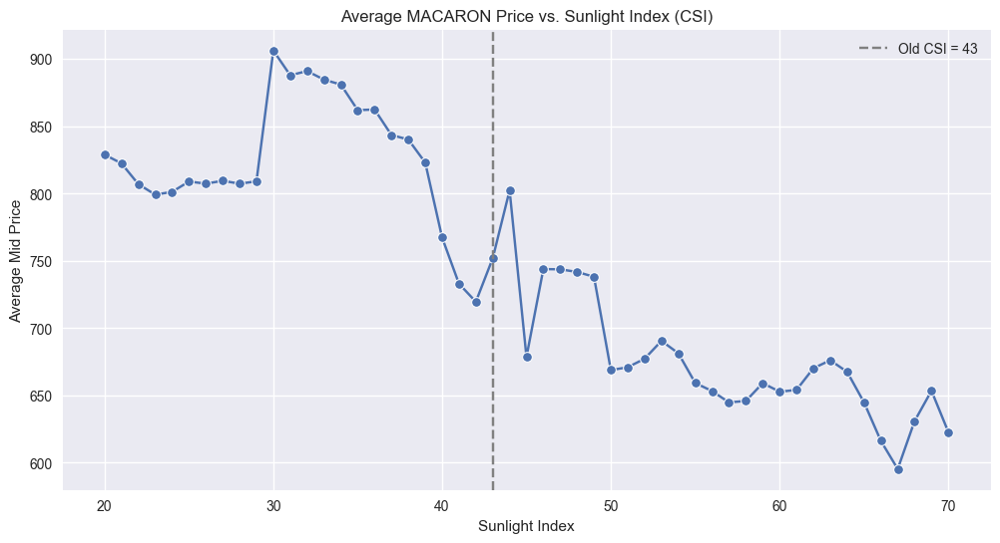

,sunlight_bin,mean_price,count,std_price
0,20,828.958904,73,10.754119
1,21,822.458333,72,9.228229
2,22,807.027027,74,24.649584
3,23,799.232877,73,26.080815
4,24,801.291667,72,20.652175
5,25,808.979730,74,21.341072
6,26,807.388889,72,22.413876
7,27,809.527027,74,12.663423
8,28,807.375000,72,9.018272
9,29,809.108108,74,11.227190


In [14]:

import seaborn as sns

# === Load merged dataset if not already ===
# (You should have this from the previous regression merge)
# It must contain: timestamp, sunlightIndex, sugarPrice, mid_price

# merged = pd.merge(mac_df, obs_df, on="timestamp").dropna()

# === Bin sunlightIndex into integer values ===
merged["sunlight_bin"] = merged["sunlightIndex"].astype(int)

# === Group by sunlight bin and compute average mid_price ===
sunlight_groups = merged.groupby("sunlight_bin").agg(
    mean_price=("mid_price", "mean"),
    count=("mid_price", "count"),
    std_price=("mid_price", "std")
).reset_index()

# === Plot it ===
plt.figure(figsize=(12, 6))
sns.lineplot(data=sunlight_groups, x="sunlight_bin", y="mean_price", marker="o")
plt.axvline(x=43, color="grey", linestyle="--", label="Old CSI = 43")
plt.title("Average MACARON Price vs. Sunlight Index (CSI)")
plt.xlabel("Sunlight Index")
plt.ylabel("Average Mid Price")
plt.grid(True)
plt.legend()
plt.show()

# === (Optional) Print raw table to inspect price shift threshold ===
display(sunlight_groups)


In [25]:
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import r2_score

# === Timestamp offsets ===
price_day_offsets = {
    "../data/prices_round_1_day_-2.csv": 0,
    "../data/prices_round_2_day_-1.csv": 1_000_000,
    "../data/prices_round_3_day_0.csv": 2_000_000,
    "../data/prices_round_4_day_1.csv": 3_000_000,
    "../data/prices_round_5_day_2.csv": 4_000_000,
    "../data/prices_round_5_day_3.csv": 5_000_000,
    "../data/prices_round_5_day_4.csv": 6_000_000,
}

obs_day_offsets = {
    "../data/observations_round_4_day_1.csv": 3_000_000,
    "../data/observations_round_4_day_2.csv": 4_000_000,
    "../data/observations_round_4_day_3.csv": 5_000_000,
    "../data/observations_round_5_day_2.csv": 4_000_000,
    "../data/observations_round_5_day_3.csv": 5_000_000,
    "../data/observations_round_5_day_4.csv": 6_000_000,
}

# === Load and merge price data ===
price_dfs = []
for file in price_day_offsets:
    df = pd.read_csv(f"Prices/{file}")
    df = df.iloc[:, 0].str.split(";", expand=True)
    df.columns = [
        "day", "timestamp", "product",
        "bid_price_1", "bid_volume_1", "bid_price_2", "bid_volume_2", "bid_price_3", "bid_volume_3",
        "ask_price_1", "ask_volume_1", "ask_price_2", "ask_volume_2", "ask_price_3", "ask_volume_3",
        "mid_price", "profit_and_loss"
    ]
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce") + price_day_offsets[file]
    numeric_cols = df.columns.difference(["day", "timestamp", "product"])
    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
    price_dfs.append(df)

price_df = pd.concat(price_dfs, ignore_index=True)
mac_df = price_df[price_df["product"] == "MAGNIFICENT_MACARONS"]
mac_df = mac_df[["timestamp", "mid_price"]].dropna()

# === Load and merge observation data ===
obs_dfs = []
for file in obs_day_offsets:
    df = pd.read_csv(f"Prices/{file}")
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce") + obs_day_offsets[file]
    df = df[["timestamp", "sugarPrice", "sunlightIndex"]]
    obs_dfs.append(df)

obs_df = pd.concat(obs_dfs, ignore_index=True)

# === Merge datasets and filter by CSI ===
merged = pd.merge(mac_df, obs_df, on="timestamp").dropna()

CSI = 44
filtered = merged[merged["sunlightIndex"] > CSI].copy()
print(f"Filtered dataset (sunlightIndex > {CSI}): {filtered.shape[0]} rows")

# === Linear regression: mid_price ~ sugarPrice only ===
X = sm.add_constant(filtered[["sugarPrice"]])
y = filtered["mid_price"]
model = sm.OLS(y, X).fit()
print(model.summary())

# === New model parameters ===
a_new = model.params["sugarPrice"]
c_new = model.params["const"]
print(f"\n✅ New Model (SI > {CSI}): fair_value = {a_new:.4f} * sugarPrice + {c_new:.4f}")

# === R² of previous (manual) model ===
filtered["fair_value_manual"] = 3.4464 * filtered["sugarPrice"] - 51.3392
r2_old = r2_score(filtered["mid_price"], filtered["fair_value_manual"])
print(f"\n📉 R² of your old model (3.4464 * sugarPrice - 51.3392): {r2_old:.4f}")


Filtered dataset (sunlightIndex > 44): 50653 rows
                            OLS Regression Results                            
Dep. Variable:              mid_price   R-squared:                       0.254
Model:                            OLS   Adj. R-squared:                  0.254
Method:                 Least Squares   F-statistic:                 1.728e+04
Date:                Mon, 21 Apr 2025   Prob (F-statistic):               0.00
Time:                        15:55:28   Log-Likelihood:            -2.8407e+05
No. Observations:               50653   AIC:                         5.681e+05
Df Residuals:                   50651   BIC:                         5.682e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
co

In [ ]:
# Use the merged DataFrame from earlier
CSI = 44
filtered = merged[merged["sunlightIndex"] > CSI].copy()
print(f"Filtered dataset (sunlightIndex > {CSI}): {filtered.shape[0]} rows")

# === Regression: mid_price ~ sugarPrice + sunlightIndex
X = filtered[["sugarPrice", "sunlightIndex"]]
X = sm.add_constant(X)
y = filtered["mid_price"]

model = sm.OLS(y, X).fit()
print(model.summary())

# === Extract model parameters
a = model.params["sugarPrice"]
b = model.params["sunlightIndex"]
c = model.params["const"]

print(f"\n📈 Model (SI > {CSI}): fair_value = {a:.4f} * sugarPrice + {b:.4f} * sunlightIndex + {c:.4f}")


Filtered dataset (sunlightIndex > 44): 50653 rows
                            OLS Regression Results                            
Dep. Variable:              mid_price   R-squared:                       0.309
Model:                            OLS   Adj. R-squared:                  0.309
Method:                 Least Squares   F-statistic:                 1.131e+04
Date:                Mon, 21 Apr 2025   Prob (F-statistic):               0.00
Time:                        15:44:28   Log-Likelihood:            -2.8215e+05
No. Observations:               50653   AIC:                         5.643e+05
Df Residuals:                   50650   BIC:                         5.643e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------